In [58]:
import numpy as np
import matplotlib.pyplot as plt
import os

In [61]:
def force_analysis(dataset_file):
    # Read the dataset file
    with open(dataset_file, 'r') as file:
        lines = file.readlines()
   
    lattice_count=1
    energies=[]
    lattice_z=[]
    mean_module_square=[]
    atom_count=0
    struct_count=0
    tmp=0
    for i , line in enumerate(lines):
        if line.startswith('lattice'):
            split_line=line.split()
            
            if lattice_count % 3 == 0:
                lattice_z.append(float(split_line[3]))
                #print(split_line[3])
            lattice_count=lattice_count+1
            
        if line.startswith('atom'):
            split_line=line.split()
            #print(split_line)
            tmp=tmp+  float(split_line[7])**2+ float(split_line[8])**2+ float(split_line[9])**2
            #print(tmp)
            atom_count=atom_count+1
          
        if line.startswith('energy'): 
            split_line=line.split()
            #print(split_line[1])
            energies.append(float(split_line[1]))
            mean_module_square.append(tmp/atom_count)
            struct_count=struct_count+1
            atom_count=0 
            tmp=0
    print(struct_count)
            
       
            
        
    
    return energies, mean_module_square, lattice_z

In [148]:
dataset_file='test_data/test.data'
dataset_file_2='committee_fifth/good_input.data'
en_for=force_analysis(dataset_file)
en_for_2=force_analysis(dataset_file_2)


1114
4221


In [149]:
energies=en_for[0]
mean_force=en_for[1]
lattice=en_for[2]
print(len(mean_force))
print(len(energies))
energies_2=en_for_2[0]
mean_force_2=en_for_2[1]
lattice_2=en_for_2[2]
print(len(mean_force_2))
print(len(energies_2))

1114
1114
4221
4221


(0.0, 6.0)

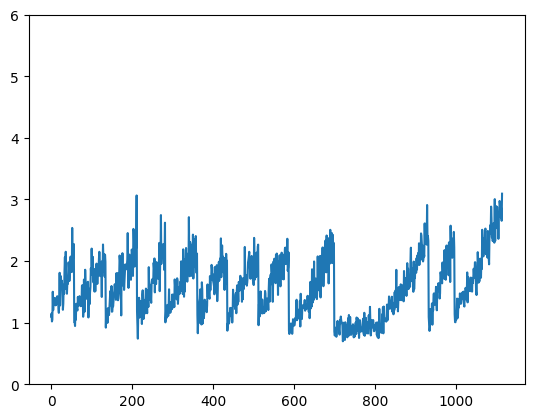

In [150]:
plt.plot(mean_force)
#plt.plot(mean_force_2)
plt.ylim(0,6)

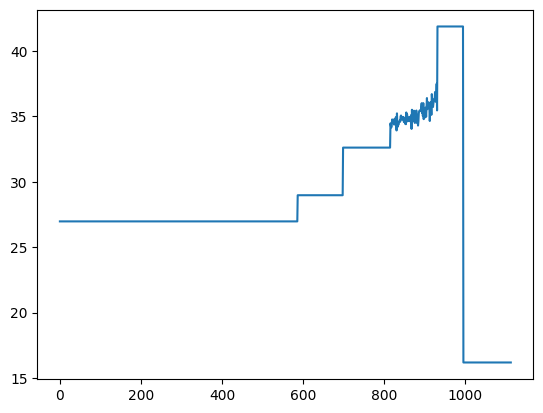

In [152]:
plt.plot(lattice)
#plt.plot(lattice_2)
#plt.xlim(3100,3700)

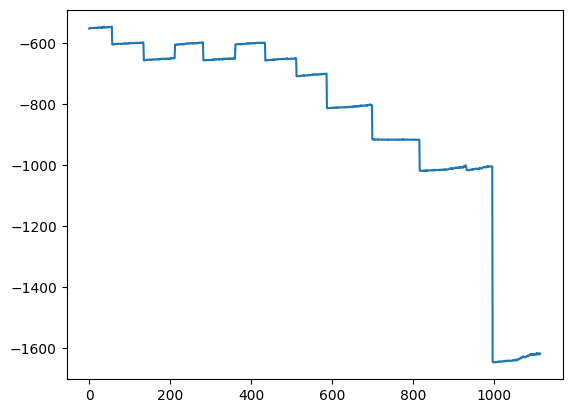

In [154]:
plt.plot(energies)
#plt.plot(energies_2[4025:])
#plt.xlim(3100,3550)

In [72]:
#further analysis forces
threeshold=5
good_indices=np.where(np.array(mean_force) < threeshold)[0]

In [74]:
print(good_indices)
print(len(good_indices))

[   0    1    2 ... 3639 3640 3641]
3634


In [75]:
good_forces=np.array(mean_force)[good_indices]

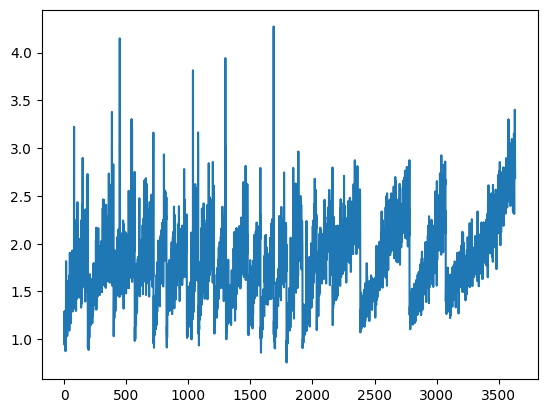

In [76]:
plt.plot(good_forces)


In [77]:
good_energies=np.array(energies)[good_indices]

array([ -552.30524448,  -551.60703063,  -552.08486955, ...,
       -1615.85454964, -1616.83844271, -1615.43050403])

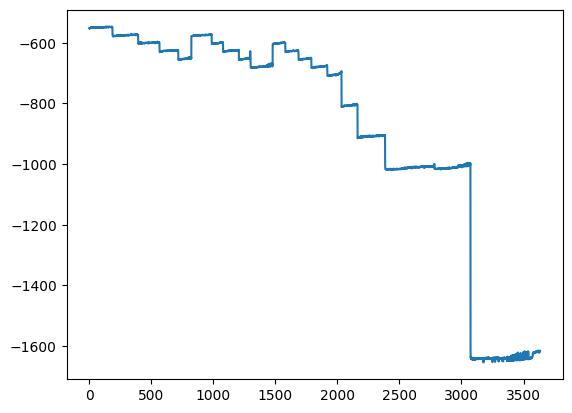

In [78]:
plt.plot(good_energies)
good_energies

In [81]:
def print_good_configurations(dataset_file, good_structures, good_dataset):
    # Read the dataset file
    with open(dataset_file, 'r') as file:
        lines = file.readlines()
  
    count=0   
    #print(index)
    with open(good_dataset, 'w') as new_file:
        index=0
        bool=True
        for i, line in enumerate(lines):
            if line.startswith('begin'): 
                if index in good_structures:
                    bool=True
                    count += 1
                else: 
                    bool=False
                index += 1
            if bool:
                new_file.write(line)
               
    print(count) 
   
    return 

In [82]:


good_dataset="./committee_sixth/good_dataset"   #name of the input.data to be cleaned
print_good_configurations(dataset_file, good_indices, good_dataset)

3634
